# EDA – Khám phá dữ liệu `master_ken_data.csv` (Mục 3.5)

Đề tài: Tích hợp hệ thống gợi ý và mô hình dự báo thông minh vào nền tảng không gian đa tiện ích KÉN.

Notebook này phục vụ hai mục của báo cáo:

- **3.5.1 Phân tích phân phối và xu hướng**: đỉnh bán hàng theo khung giờ, ngày thường so với cuối tuần, biến động theo tháng, cơ cấu món.
- **3.5.2 Phân tích tương quan đặc trưng**: ma trận tương quan, tự tương quan theo ngày, từ đó rút ra nhận định để thiết kế đặc trưng cho 3 bài toán.

Quy ước: file CSV chỉ **đọc**, không sửa. Hình lưu vào thư mục `figures/` (tiền tố `eda_`) để chèn vào báo cáo. Khi chạy xong, các số liệu chính được ghi vào `figures/eda_summary.json`.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.unicode_minus"] = False

DATA = Path("..") / "data" / "master_ken_data.csv"
FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
SUMMARY = {}          # gom số liệu để điền vào báo cáo

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"eda_{name}.png", dpi=170, bbox_inches="tight")
    plt.show()

## 0. Nạp dữ liệu và đối chiếu với mô tả

In [2]:
df = pd.read_csv(DATA, dtype={"order_code": str, "booking_id": str, "customer_id": str, "item_id": str})
df["sale_date"] = pd.to_datetime(df["sale_date"])

n_booking = df.loc[df["booking_id"].notna(), "booking_id"].nunique()
n_customer = df.loc[df["customer_id"].notna(), "customer_id"].nunique()
n_days = df["sale_date"].nunique()
span_days = (df["sale_date"].max() - df["sale_date"].min()).days + 1

check = pd.DataFrame({
    "Chỉ tiêu": ["Số dòng", "Số cột", "Ngày đầu", "Ngày cuối", "Số ngày có bán", "Số ngày theo lịch",
                 "Số món F&B", "Số booking", "Số khách đăng nhập"],
    "Thực tế": [len(df), df.shape[1], df["sale_date"].min().date(), df["sale_date"].max().date(), n_days, span_days,
                df["item_code"].nunique(), n_booking, n_customer],
    "Mô tả (A1)": [67375, 30, "2026-04-01", "2026-10-27", 210, 210, 31, 8350, 312],
})
check["Khớp"] = check.apply(lambda r: "có" if str(r["Thực tế"]) == str(r["Mô tả (A1)"]) else "KHÔNG", axis=1)
display(check)
SUMMARY["schema_check"] = check.astype(str).to_dict(orient="records")
df.head(3)

,Chỉ tiêu,Thực tế,Mô tả (A1),Khớp
0,Số dòng,67375,67375,có
1,Số cột,30,30,có
2,Ngày đầu,2026-04-01,2026-04-01,có
3,Ngày cuối,2026-10-27,2026-10-27,có
4,Số ngày có bán,210,210,có
5,Số ngày theo lịch,210,210,có
6,Số món F&B,31,31,có
7,Số booking,8350,8350,có
8,Số khách đăng nhập,312,312,có


,order_code,booking_id,customer_id,sale_date,hour_of_day,time_part,day_of_week,day_name,is_weekend,month,season,item_id,item_code,item_name,category,sub_category,item_type,quantity,unit_price_vnd,line_total_vnd,source,is_inclusion,is_walk_in,tier_code,zone_code,zone_name,space_type,guest_count,booking_duration_hours,customer_age
0,ORD-000001,NaN,NaN,2026-04-01,8,Morning,2,Thứ 4,0,4,DRY,a9d7e0aaed024132acc4efaf,CF_PHIN,Cà phê phin truyền thống,DRINK,COFFEE,DRINK,1,35000,35000,SYNTHETIC,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ORD-000002,NaN,NaN,2026-04-01,8,Morning,2,Thứ 4,0,4,DRY,b002a0099cef605019980607,CF_BAC_XIU,Bạc xỉu,DRINK,COFFEE,DRINK,1,45000,45000,SYNTHETIC,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ORD-000002,NaN,NaN,2026-04-01,8,Morning,2,Thứ 4,0,4,DRY,ee4e977f969d9a87c6e9ada1,CF_COLD_BREW,Cold Brew truyền thống,DRINK,COFFEE,DRINK,1,50000,50000,SYNTHETIC,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Chất lượng dữ liệu

In [3]:
exp_blank = ["booking_id", "customer_id", "tier_code", "zone_code", "zone_name", "space_type",
             "guest_count", "booking_duration_hours", "customer_age"]
miss = df.isna().sum().rename("số ô rỗng").to_frame()
miss["tỷ lệ"] = (miss["số ô rỗng"] / len(df)).round(4)
display(miss[miss["số ô rỗng"] > 0])

# Cột booking/khách phải rỗng đúng với khách vãng lai, và chỉ với khách vãng lai
walk = df["is_walk_in"] == 1
ok_blank = (df.loc[walk, exp_blank].isna().all().all()) and (df.loc[~walk, exp_blank].notna().all().all())
print("Ô rỗng khớp đúng với khách vãng lai:", ok_blank)

print("Dòng trùng lặp hoàn toàn:", df.duplicated().sum())
print("quantity:", df["quantity"].min(), "→", df["quantity"].max(), "| hour_of_day:", df["hour_of_day"].min(), "→", df["hour_of_day"].max())
print("line_total_vnd = quantity × unit_price_vnd ở mọi dòng:", bool((df["line_total_vnd"] == df["quantity"] * df["unit_price_vnd"]).all()))
print("Dòng quyền lợi đều có giá 0:", bool((df.loc[df["is_inclusion"] == 1, "unit_price_vnd"] == 0).all()))

full = pd.date_range(df["sale_date"].min(), df["sale_date"].max())
print("Ngày bị thiếu trong khoảng:", len(full.difference(df["sale_date"].unique())))
cell = df.groupby(["sale_date", "item_code"]).size().unstack(fill_value=0).reindex(full, fill_value=0)
empty_cells = int((cell == 0).sum().sum())
print(f"Số cặp (ngày, món) không có dòng nào: {empty_cells} → cần fillna(0) khi dự báo (Bài 2)")
SUMMARY["empty_day_item_pairs"] = empty_cells

,số ô rỗng,tỷ lệ
booking_id,39068,0.5799
customer_id,39068,0.5799
tier_code,39068,0.5799
zone_code,39068,0.5799
zone_name,39068,0.5799
space_type,39068,0.5799
guest_count,39068,0.5799
booking_duration_hours,39068,0.5799
customer_age,39068,0.5799


Ô rỗng khớp đúng với khách vãng lai: True
Dòng trùng lặp hoàn toàn: 0
quantity: 1 → 10 | hour_of_day: 8 → 21
line_total_vnd = quantity × unit_price_vnd ở mọi dòng: True
Dòng quyền lợi đều có giá 0: True
Ngày bị thiếu trong khoảng: 0
Số cặp (ngày, món) không có dòng nào: 7 → cần fillna(0) khi dự báo (Bài 2)


## 2. Hai loại dòng cần phân biệt

- **Khách vãng lai** (`is_walk_in = 1`): không có booking, không có `customer_id`.
- **Dòng quyền lợi** (`is_inclusion = 1`): món tặng kèm theo gói, giá 0, khách không chủ động chọn.

,số dòng,tỷ_lệ
Khách vãng lai,39068,0.5799
Dòng quyền lợi (tặng kèm),13679,0.2030
Dòng khách đăng nhập tự chọn mua,14628,0.2171


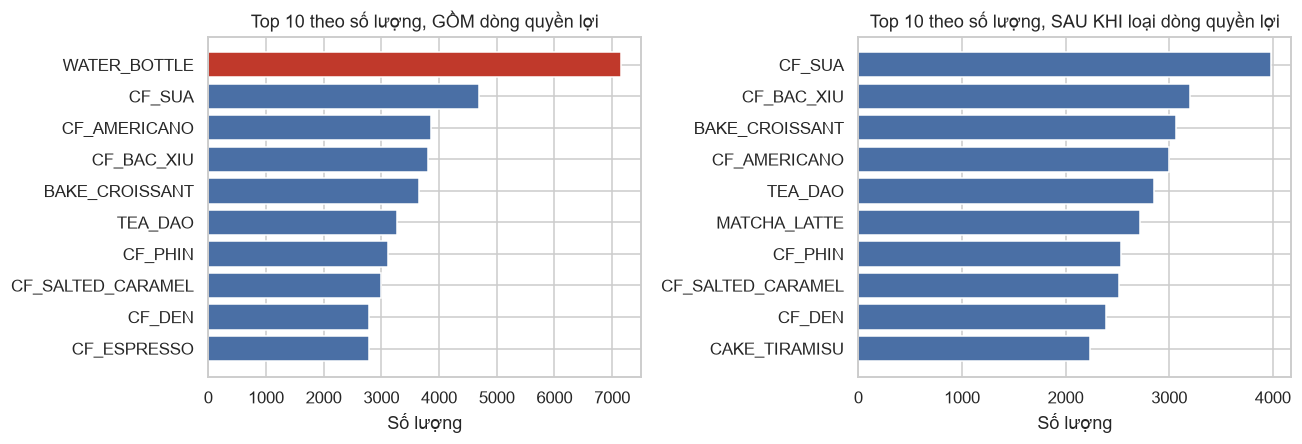

WATER_BOTTLE: 73.4% số lượng đến từ dòng quyền lợi


In [4]:
n = len(df)
types = pd.Series({
    "Khách vãng lai": int((df["is_walk_in"] == 1).sum()),
    "Dòng quyền lợi (tặng kèm)": int((df["is_inclusion"] == 1).sum()),
    "Dòng khách đăng nhập tự chọn mua": int(((df["is_walk_in"] == 0) & (df["is_inclusion"] == 0)).sum()),
})
display((types.to_frame("số dòng").assign(tỷ_lệ=lambda x: (x["số dòng"] / n).round(4))))
SUMMARY["walk_in_share"] = float(types.iloc[0] / n)
SUMMARY["inclusion_share"] = float(types.iloc[1] / n)

buy = df[df["is_inclusion"] == 0].copy()          # dòng khách chủ động mua (dùng cho Bài 1, 2, 3)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
a = df.groupby("item_code")["quantity"].sum().sort_values(ascending=False).head(10)[::-1]
b = buy.groupby("item_code")["quantity"].sum().sort_values(ascending=False).head(10)[::-1]
ax[0].barh(a.index, a.values, color=["#c0392b" if i == "WATER_BOTTLE" else "#4a6fa5" for i in a.index]); ax[0].set_title("Top 10 theo số lượng, GỒM dòng quyền lợi")
ax[1].barh(b.index, b.values, color="#4a6fa5"); ax[1].set_title("Top 10 theo số lượng, SAU KHI loại dòng quyền lợi")
for x in ax: x.set_xlabel("Số lượng")
savefig("inclusion_effect")

wb = df[df["item_code"] == "WATER_BOTTLE"]
if len(wb):
    share_incl = wb.loc[wb["is_inclusion"] == 1, "quantity"].sum() / wb["quantity"].sum()
    print(f"WATER_BOTTLE: {share_incl:.1%} số lượng đến từ dòng quyền lợi")
    SUMMARY["water_bottle_inclusion_share"] = float(share_incl)

## 3. Mục 3.5.1 – Phân phối và xu hướng

Từ đây dùng `buy` (đã loại dòng quyền lợi); khách vãng lai được giữ vì Bài 1 và Bài 2 dùng cả nhóm này.

### 3.1 Đỉnh bán hàng theo khung giờ

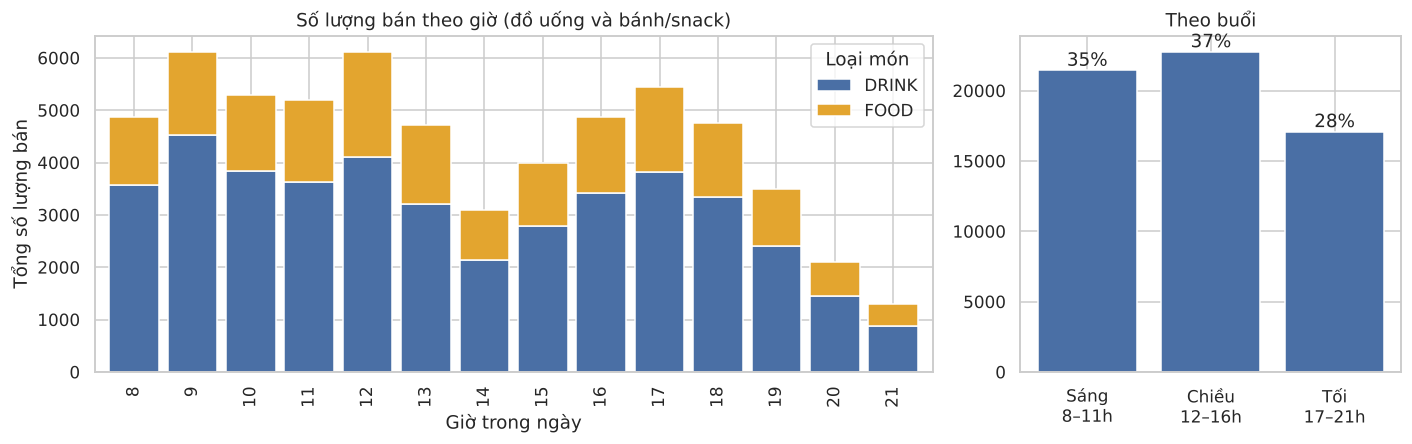

Giờ cao điểm: 12h (6,119 đơn vị) | giờ thấp điểm: 21h (1,289) | tỷ lệ cao/thấp: 4.7 lần
Tỷ trọng theo buổi: {'Morning': 0.35, 'Afternoon': 0.371, 'Evening': 0.279}


In [5]:
by_hour = buy.groupby("hour_of_day")["quantity"].sum()
by_hour_type = buy.groupby(["hour_of_day", "item_type"])["quantity"].sum().unstack(fill_value=0)
part_order = ["Morning", "Afternoon", "Evening"]
by_part = buy.groupby("time_part")["quantity"].sum().reindex(part_order)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
by_hour_type.plot(kind="bar", stacked=True, ax=ax[0], color=["#4a6fa5", "#e3a52f"], width=0.85)
ax[0].set_xlabel("Giờ trong ngày"); ax[0].set_ylabel("Tổng số lượng bán"); ax[0].set_title("Số lượng bán theo giờ (đồ uống và bánh/snack)"); ax[0].legend(title="Loại món")
ax[1].bar(["Sáng\n8–11h", "Chiều\n12–16h", "Tối\n17–21h"], by_part.values, color="#4a6fa5")
for i, v in enumerate(by_part.values): ax[1].text(i, v, f"{v/by_part.sum():.0%}", ha="center", va="bottom")
ax[1].set_title("Theo buổi")
savefig("hour")

peak = int(by_hour.idxmax()); low = int(by_hour.idxmin())
print(f"Giờ cao điểm: {peak}h ({by_hour.max():,} đơn vị) | giờ thấp điểm: {low}h ({by_hour.min():,}) | tỷ lệ cao/thấp: {by_hour.max()/by_hour.min():.1f} lần")
print("Tỷ trọng theo buổi:", (by_part / by_part.sum()).round(3).to_dict())
SUMMARY.update(peak_hour=peak, low_hour=low, part_share=(by_part / by_part.sum()).round(4).to_dict())

### 3.2 Ngày thường và cuối tuần

,total_qty,total_rev
Ngày thường,264.0,11380333.0
Cuối tuần,361.0,15703917.0


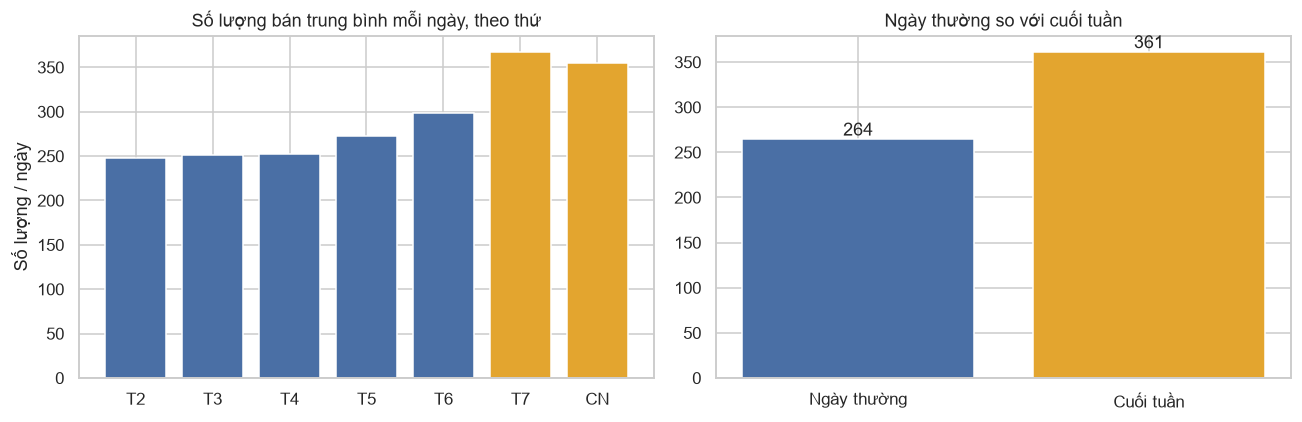

Cuối tuần cao hơn ngày thường 36.6% về số lượng bán trung bình/ngày


In [5]:
daily = buy.groupby("sale_date").agg(total_qty=("quantity", "sum"), total_rev=("line_total_vnd", "sum"),
                                     n_orders=("order_code", "nunique")).reindex(full, fill_value=0)
daily["day_of_week"] = daily.index.dayofweek
daily["is_weekend"] = (daily["day_of_week"] >= 5).astype(int)
daily["month"] = daily.index.month

dow_names = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
dow = daily.groupby("day_of_week")[["total_qty", "total_rev"]].mean()
we = daily.groupby("is_weekend")[["total_qty", "total_rev"]].mean()
we.index = ["Ngày thường", "Cuối tuần"]
display(we.round(0))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(dow_names, dow["total_qty"], color=["#4a6fa5"] * 5 + ["#e3a52f"] * 2)
ax[0].set_title("Số lượng bán trung bình mỗi ngày, theo thứ"); ax[0].set_ylabel("Số lượng / ngày")
ax[1].bar(we.index, we["total_qty"], color=["#4a6fa5", "#e3a52f"])
for i, v in enumerate(we["total_qty"]): ax[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom")
ax[1].set_title("Ngày thường so với cuối tuần")
savefig("weekday_weekend")

diff = we.loc["Cuối tuần", "total_qty"] / we.loc["Ngày thường", "total_qty"] - 1
print(f"Cuối tuần {'cao' if diff >= 0 else 'thấp'} hơn ngày thường {abs(diff):.1%} về số lượng bán trung bình/ngày")
SUMMARY["weekend_vs_weekday_qty_pct"] = float(diff)
SUMMARY["dow_mean_qty"] = dict(zip(dow_names, dow["total_qty"].round(1)))

### 3.3 Biến động theo tháng và theo thời gian

,days,qty_per_day,rev_per_day
month,,,
4,30,273.2,11879500.0
5,31,295.7,12777580.6
6,30,282.8,12197833.3
7,31,285.2,12280967.7
8,31,296.8,12808871.0
9,30,307.5,13312166.7
10,27,303.7,13100370.4


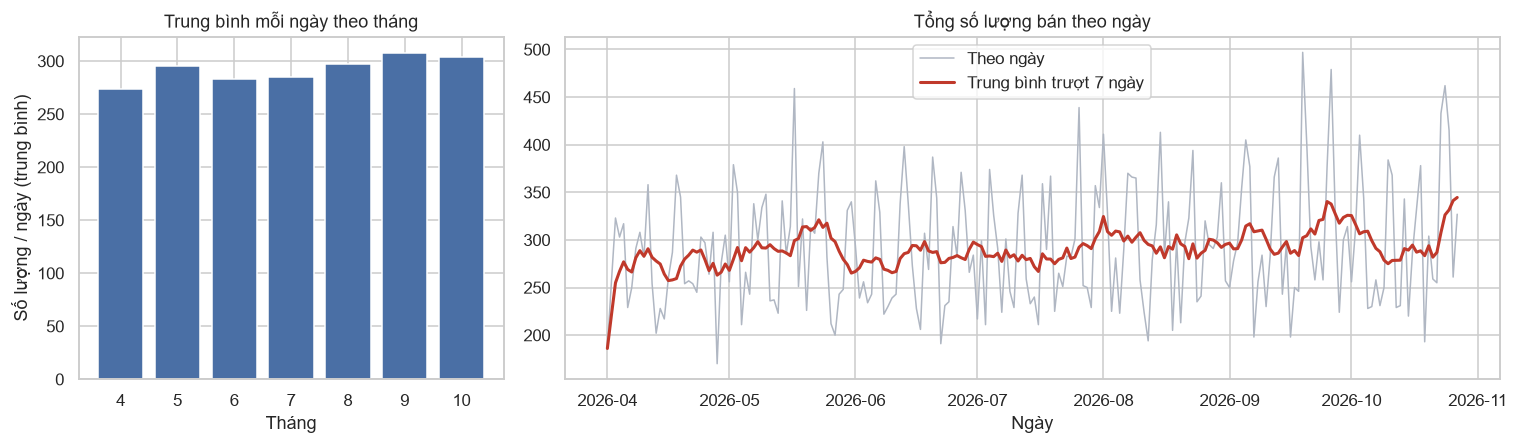

28 ngày đầu: 272/ngày | 28 ngày cuối: 304/ngày | thay đổi +11.8%
Lưu ý: tháng 4 có đủ ngày nhưng tháng 10 chỉ đến 27/10, nên so sánh tháng dùng trung bình mỗi ngày, không dùng tổng.
Số tháng có season = DRY: [np.int64(4)]


In [6]:
mon = daily.groupby("month").agg(days=("total_qty", "size"), qty_per_day=("total_qty", "mean"), rev_per_day=("total_rev", "mean"))
display(mon.round(1))
daily["ma7"] = daily["total_qty"].rolling(7, min_periods=1).mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
ax[0].bar(mon.index.astype(str), mon["qty_per_day"], color="#4a6fa5"); ax[0].set_xlabel("Tháng"); ax[0].set_ylabel("Số lượng / ngày (trung bình)")
ax[0].set_title("Trung bình mỗi ngày theo tháng")
ax[1].plot(daily.index, daily["total_qty"], color="#b0b7c3", lw=1, label="Theo ngày")
ax[1].plot(daily.index, daily["ma7"], color="#c0392b", lw=2, label="Trung bình trượt 7 ngày")
ax[1].set_title("Tổng số lượng bán theo ngày"); ax[1].legend(); ax[1].set_xlabel("Ngày")
savefig("monthly_trend")

first28, last28 = daily["total_qty"].iloc[:28].mean(), daily["total_qty"].iloc[-28:].mean()
print(f"28 ngày đầu: {first28:.0f}/ngày | 28 ngày cuối: {last28:.0f}/ngày | thay đổi {last28/first28-1:+.1%}")
print("Lưu ý: tháng 4 có đủ ngày nhưng tháng 10 chỉ đến 27/10, nên so sánh tháng dùng trung bình mỗi ngày, không dùng tổng.")
print("Số tháng có season = DRY:", sorted(buy.loc[buy["season"] == "DRY", "month"].unique()))
SUMMARY.update(qty_per_day_first28=float(first28), qty_per_day_last28=float(last28),
               dry_months=[int(m) for m in sorted(buy.loc[buy["season"] == "DRY", "month"].unique())])

### 3.4 Cơ cấu món và vì sao cần cả số lượng lẫn doanh thu

,quantity,revenue,qty_share,rev_share
item_type,,,,
DRINK,43108,1906515000,0.703,0.72
FOOD,18210,742770000,0.297,0.28


,quantity,revenue
category,,
DRINK,43108,1906515000
PASTRY,14887,599355000
SNACK,3323,143415000


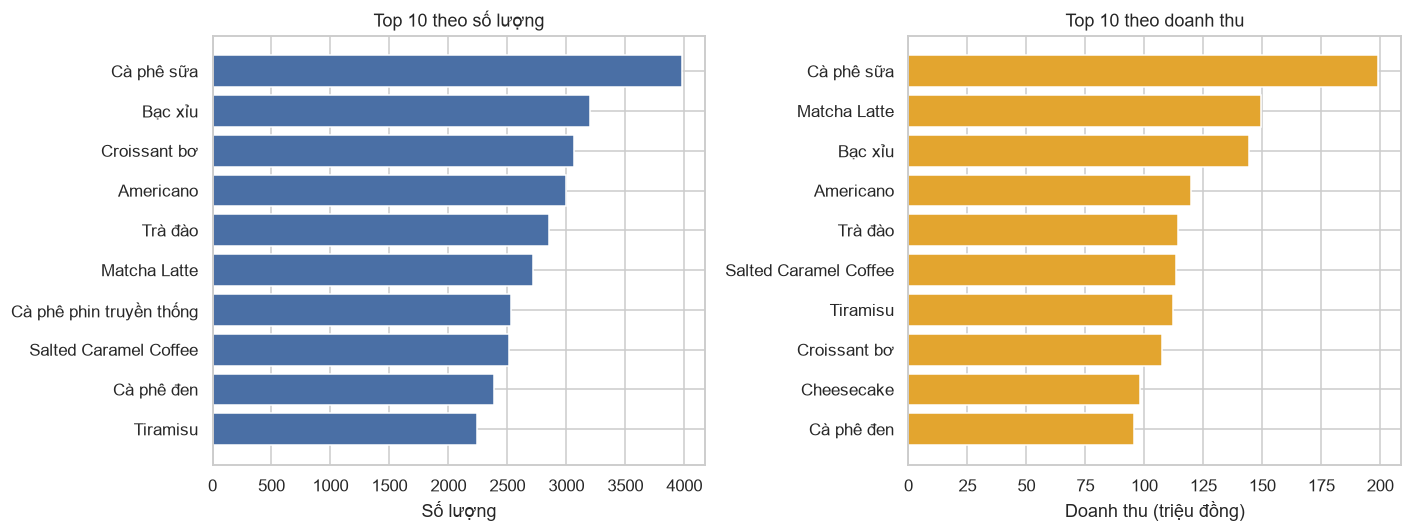

Spearman giữa hạng số lượng và hạng doanh thu: 0.85; trùng 4/5 món trong Top 5 hai bảng; lệch hạng lớn nhất 15 bậc


In [8]:
mix = buy.groupby("item_type").agg(quantity=("quantity", "sum"), revenue=("line_total_vnd", "sum"))
mix["qty_share"] = mix["quantity"] / mix["quantity"].sum(); mix["rev_share"] = mix["revenue"] / mix["revenue"].sum()
display(mix.round(3))
cat = buy.groupby("category").agg(quantity=("quantity", "sum"), revenue=("line_total_vnd", "sum"))
display(cat)

item = buy.groupby(["item_code", "item_name", "item_type"]).agg(quantity=("quantity", "sum"), revenue=("line_total_vnd", "sum"),
                                                                price=("unit_price_vnd", "median")).reset_index()
item["rank_qty"] = item["quantity"].rank(ascending=False, method="first").astype(int)
item["rank_rev"] = item["revenue"].rank(ascending=False, method="first").astype(int)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
q10 = item.nlargest(10, "quantity")[::-1]; r10 = item.nlargest(10, "revenue")[::-1]
ax[0].barh(q10["item_name"], q10["quantity"], color="#4a6fa5"); ax[0].set_title("Top 10 theo số lượng"); ax[0].set_xlabel("Số lượng")
ax[1].barh(r10["item_name"], r10["revenue"] / 1e6, color="#e3a52f"); ax[1].set_title("Top 10 theo doanh thu"); ax[1].set_xlabel("Doanh thu (triệu đồng)")
savefig("top_items")

rho = item["quantity"].corr(item["revenue"], method="spearman")
overlap = len(set(item.nsmallest(5, "rank_qty")["item_code"]) & set(item.nsmallest(5, "rank_rev")["item_code"]))
moved = (item["rank_qty"] - item["rank_rev"]).abs().max()
print(f"Spearman giữa hạng số lượng và hạng doanh thu: {rho:.2f}; trùng {overlap}/5 món trong Top 5 hai bảng; lệch hạng lớn nhất {moved} bậc")
SUMMARY.update(spearman_qty_rev=float(rho), top5_overlap=int(overlap), max_rank_shift=int(moved),
               drink_qty_share=float(mix.loc["DRINK", "qty_share"]) if "DRINK" in mix.index else None)

### 3.5 Món đang lên và món đang xuống

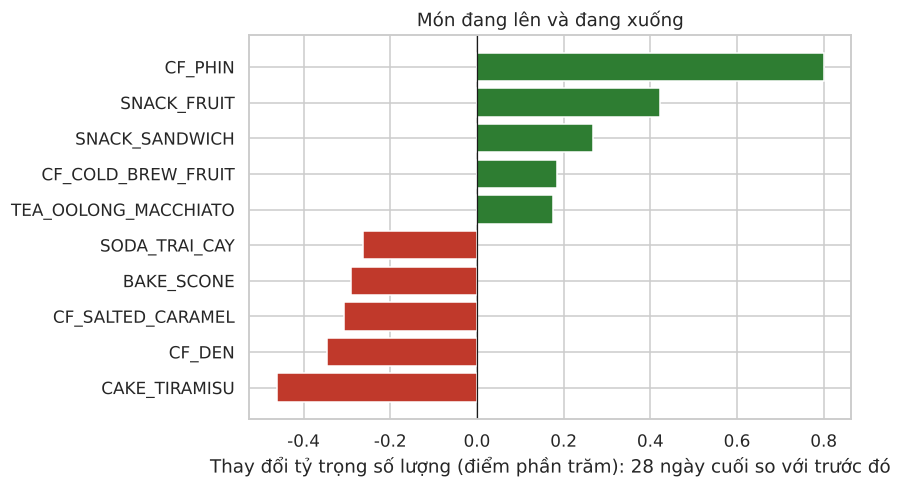

Món lên nhiều nhất: ['CF_PHIN', 'SNACK_FRUIT', 'SNACK_SANDWICH'] | xuống nhiều nhất: ['CAKE_TIRAMISU', 'CF_DEN', 'CF_SALTED_CARAMEL']
Độ lệch tỷ trọng lớn nhất: +0.80 / -0.46 điểm %


In [9]:
last_day = buy["sale_date"].max()
recent = buy[buy["sale_date"] > last_day - pd.Timedelta(days=28)]
earlier = buy[buy["sale_date"] <= last_day - pd.Timedelta(days=28)]
share = pd.DataFrame({
    "share_all_before": earlier.groupby("item_code")["quantity"].sum() / earlier["quantity"].sum(),
    "share_last28": recent.groupby("item_code")["quantity"].sum() / recent["quantity"].sum(),
}).fillna(0)
share["change_pp"] = (share["share_last28"] - share["share_all_before"]) * 100
share["ratio"] = share["share_last28"] / share["share_all_before"].replace(0, np.nan)
mv = share.sort_values("change_pp")
sel = pd.concat([mv.head(5), mv.tail(5)])

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(sel.index, sel["change_pp"], color=["#c0392b" if v < 0 else "#2e7d32" for v in sel["change_pp"]])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Thay đổi tỷ trọng số lượng (điểm phần trăm): 28 ngày cuối so với trước đó")
ax.set_title("Món đang lên và đang xuống")
savefig("rising_falling")

print("Món lên nhiều nhất:", mv.tail(3).index.tolist()[::-1], "| xuống nhiều nhất:", mv.head(3).index.tolist())
print(f"Độ lệch tỷ trọng lớn nhất: +{mv['change_pp'].max():.2f} / {mv['change_pp'].min():.2f} điểm %")
SUMMARY.update(rising=mv.tail(3).index.tolist()[::-1], falling=mv.head(3).index.tolist(),
               max_share_change_pp=float(mv["change_pp"].abs().max()))

### 3.6 Ngữ cảnh đặt chỗ của khách đăng nhập (liên quan Bài 3)

,R,F,M
count,312.0,312.0,312.0
mean,21.6,26.8,2333862.2
std,37.9,22.9,1979952.4
min,1.0,1.0,45000.0
25%,3.0,9.0,853750.0
50%,6.0,21.0,1850000.0
75%,19.0,37.0,3042500.0
max,195.0,131.0,10495000.0


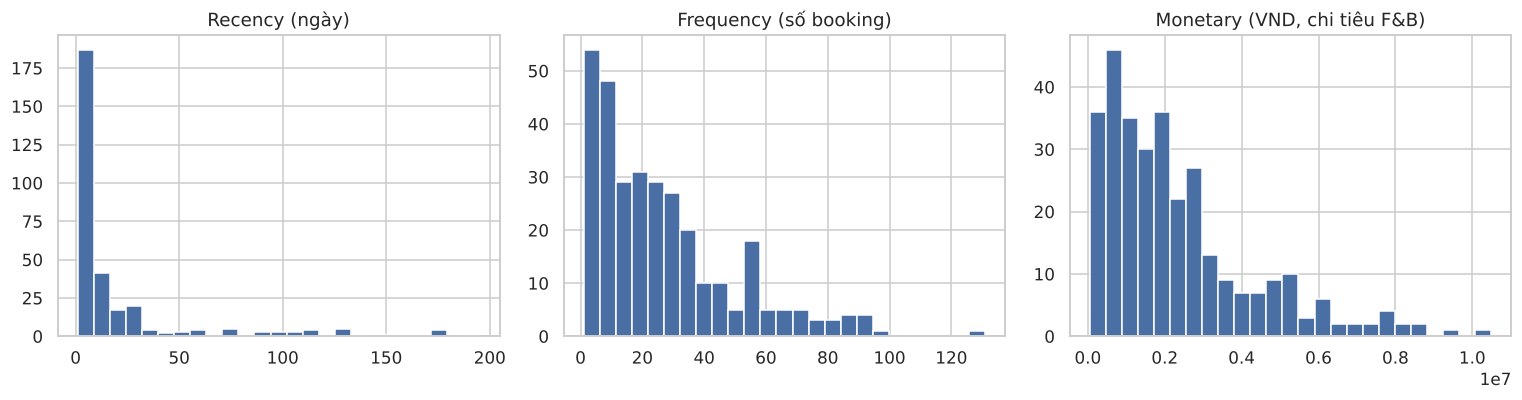

Độ lệch (skewness): {'R': 2.62, 'F': 1.33, 'M': 1.4} | trung vị M chia trung vị F ≈ 88095
Hạng thành viên: {'BASIC': 3928, 'SILVER': 3340, 'GOLD': 902, 'DIAMOND': 180}
Phân khu: {'KEN_TAP_TRUNG': 7321, 'KEN_TAI_TAO': 1029}
Loại không gian: {'WORK_LOUNGE': 6650, 'BED_POD': 659, 'FOCUS_POD': 482, 'STUDIO': 370, 'MEETING_ROOM': 189}


In [10]:
reg = buy[buy["is_walk_in"] == 0]
rfm = reg.groupby("customer_id").agg(F=("booking_id", "nunique"), M=("line_total_vnd", "sum"),
                                     last=("sale_date", "max"))
ref = df["sale_date"].max() + pd.Timedelta(days=1)
rfm["R"] = (ref - rfm["last"]).dt.days
display(rfm[["R", "F", "M"]].describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c, t in zip(ax, ["R", "F", "M"], ["Recency (ngày)", "Frequency (số booking)", "Monetary (VND, chi tiêu F&B)"]):
    a.hist(rfm[c], bins=25, color="#4a6fa5"); a.set_title(t)
savefig("rfm_distribution")

skew = rfm[["R", "F", "M"]].skew().round(2)
scale_ratio = rfm["M"].median() / rfm["F"].median()
print("Độ lệch (skewness):", skew.to_dict(), "| trung vị M chia trung vị F ≈", round(scale_ratio))
print("Hạng thành viên:", reg.drop_duplicates("booking_id")["tier_code"].value_counts().to_dict())
print("Phân khu:", reg.drop_duplicates("booking_id")["zone_code"].value_counts().to_dict())
print("Loại không gian:", reg.drop_duplicates("booking_id")["space_type"].value_counts().to_dict())
SUMMARY.update(n_customers_rfm=int(len(rfm)), rfm_skew=skew.to_dict(), m_over_f_median=float(scale_ratio))

## 4. Mục 3.5.2 – Tương quan đặc trưng

### 4.1 Ma trận tương quan theo ngày

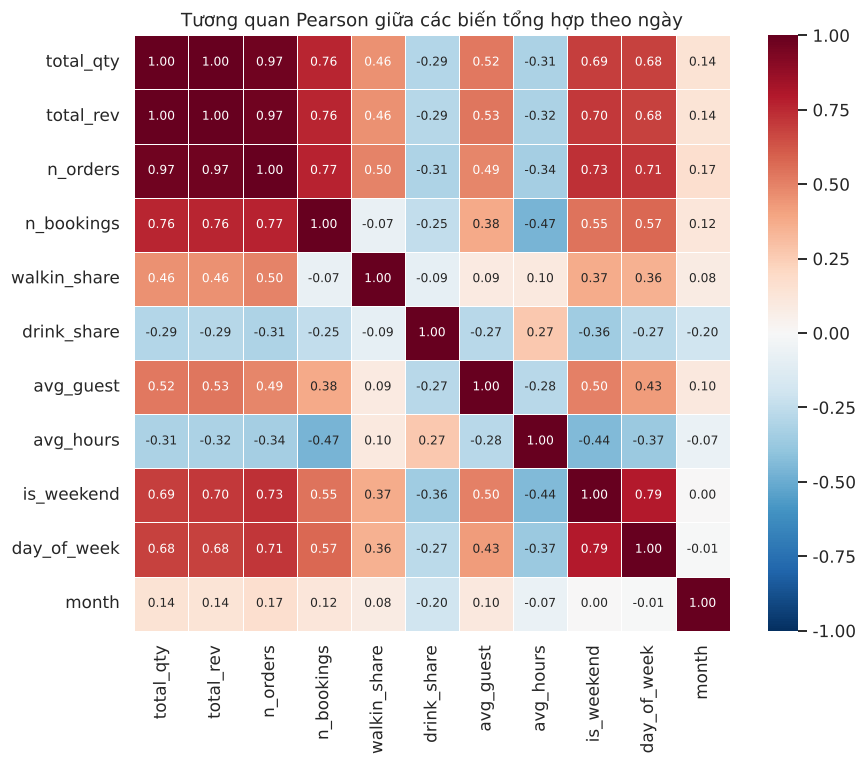

Tương quan với total_qty (theo độ lớn):


,r
total_rev,0.998
n_orders,0.974
n_bookings,0.762
is_weekend,0.694
day_of_week,0.682
avg_guest,0.524
walkin_share,0.458
avg_hours,-0.314
drink_share,-0.292
month,0.144


In [11]:
bk = df[df["is_walk_in"] == 0].groupby("sale_date")["booking_id"].nunique().reindex(full, fill_value=0)
ctx = df[df["is_walk_in"] == 0].drop_duplicates("booking_id").groupby("sale_date").agg(
    avg_guest=("guest_count", "mean"), avg_hours=("booking_duration_hours", "mean")).reindex(full)
type_q = buy.pivot_table(index="sale_date", columns="item_type", values="quantity", aggfunc="sum", fill_value=0).reindex(full, fill_value=0)

D = pd.DataFrame({
    "total_qty": daily["total_qty"], "total_rev": daily["total_rev"], "n_orders": daily["n_orders"],
    "n_bookings": bk, "walkin_share": buy.groupby("sale_date").apply(lambda g: (g["is_walk_in"] == 1).mean()).reindex(full),
    "drink_share": type_q["DRINK"] / type_q.sum(axis=1),
    "avg_guest": ctx["avg_guest"], "avg_hours": ctx["avg_hours"],
    "is_weekend": daily["is_weekend"], "day_of_week": daily["day_of_week"], "month": daily["month"],
})
corr = D.corr(method="pearson")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax, annot_kws={"size": 8})
ax.set_title("Tương quan Pearson giữa các biến tổng hợp theo ngày")
savefig("corr_daily")

c = corr["total_qty"].drop("total_qty").sort_values(key=abs, ascending=False)
print("Tương quan với total_qty (theo độ lớn):"); display(c.round(3).to_frame("r"))
SUMMARY["corr_with_total_qty"] = c.round(3).to_dict()

### 4.2 Tương quan giữa nhu cầu các món

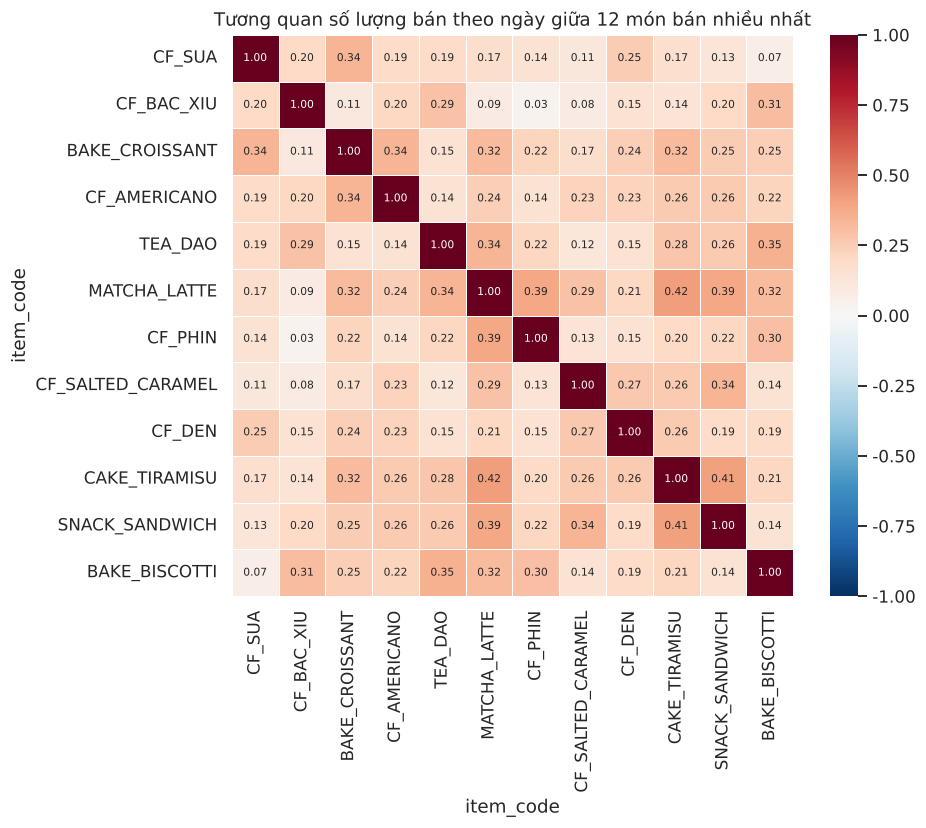

Tương quan giữa các cặp món: trung bình 0.22, cao nhất 0.42, thấp nhất 0.03


In [12]:
dm = buy.pivot_table(index="sale_date", columns="item_code", values="quantity", aggfunc="sum", fill_value=0).reindex(full, fill_value=0)
top12 = dm.sum().nlargest(12).index
cm = dm[top12].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.4, ax=ax, annot_kws={"size": 7})
ax.set_title("Tương quan số lượng bán theo ngày giữa 12 món bán nhiều nhất")
savefig("corr_items")
off = cm.where(~np.eye(len(cm), dtype=bool)).stack()
print(f"Tương quan giữa các cặp món: trung bình {off.mean():.2f}, cao nhất {off.max():.2f}, thấp nhất {off.min():.2f}")
SUMMARY.update(item_corr_mean=float(off.mean()), item_corr_max=float(off.max()), item_corr_min=float(off.min()))

### 4.3 Tự tương quan theo ngày (cơ sở cho đặc trưng lag của Bài 2)

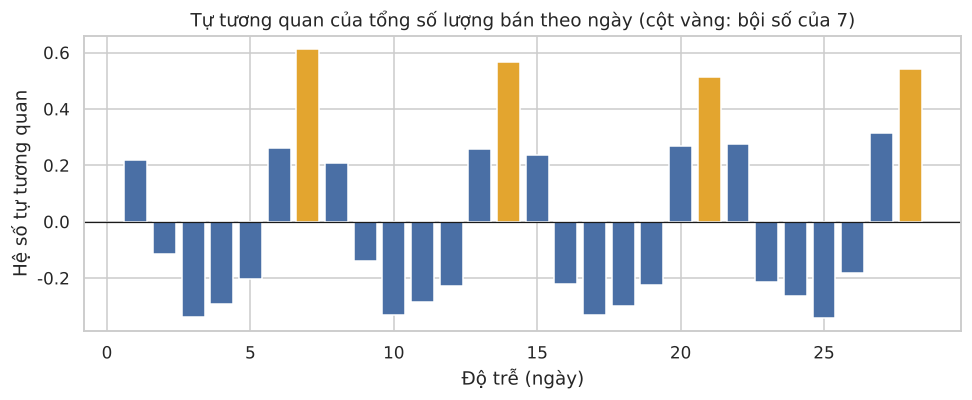

Tự tương quan lag 1 = 0.22, lag 7 = 0.61, lag 14 = 0.57, lag 28 = 0.54; lag cao nhất (từ 2 trở đi) = 7
{'unit_price_vnd': 0.002, 'hour_of_day': 0.0, 'is_weekend': -0.003}


In [13]:
s = daily["total_qty"].astype(float)
acf = pd.Series({k: s.autocorr(lag=k) for k in range(1, 29)})
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(acf.index, acf.values, color=["#e3a52f" if k % 7 == 0 else "#4a6fa5" for k in acf.index])
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("Độ trễ (ngày)"); ax.set_ylabel("Hệ số tự tương quan")
ax.set_title("Tự tương quan của tổng số lượng bán theo ngày (cột vàng: bội số của 7)")
savefig("acf")
best = acf.drop(index=[1]).idxmax()
print(f"Tự tương quan lag 1 = {acf[1]:.2f}, lag 7 = {acf[7]:.2f}, lag 14 = {acf[14]:.2f}, lag 28 = {acf[28]:.2f}; lag cao nhất (từ 2 trở đi) = {best}")
SUMMARY.update(acf_lag1=float(acf[1]), acf_lag7=float(acf[7]), acf_lag14=float(acf[14]), acf_best_lag=int(best))

# Tương quan ở cấp dòng: giá, giờ so với số lượng
line = buy[["quantity", "unit_price_vnd", "hour_of_day", "is_weekend"]]
print(line.corr(method="spearman").round(3)["quantity"].drop("quantity").to_dict())

## 5. Nhận định và hàm ý thiết kế đặc trưng

In [14]:
d = SUMMARY
lines = []
lines.append(f"Dữ liệu: {len(df):,} dòng, {n_days} ngày liên tục, {df['item_code'].nunique()} món; khách vãng lai chiếm {d['walk_in_share']:.0%} số dòng, dòng quyền lợi {d['inclusion_share']:.0%}.")
if "water_bottle_inclusion_share" in d:
    lines.append(f"WATER_BOTTLE: {d['water_bottle_inclusion_share']:.0%} số lượng đến từ dòng quyền lợi, nên phải loại dòng quyền lợi trước khi tính Trending (Bài 1) và khi tính gợi ý theo cụm (Bài 3).")
lines.append(f"Giờ cao điểm là {d['peak_hour']}h, thấp điểm là {d['low_hour']}h; sáng {d['part_share']['Morning']:.0%}, chiều {d['part_share']['Afternoon']:.0%}, tối {d['part_share']['Evening']:.0%} tổng số lượng.")
lines.append(f"Cuối tuần {'cao' if d['weekend_vs_weekday_qty_pct']>=0 else 'thấp'} hơn ngày thường {abs(d['weekend_vs_weekday_qty_pct']):.1%} về số lượng/ngày → dùng đặc trưng thứ trong tuần và cờ cuối tuần (Bài 2).")
lines.append(f"Spearman giữa hạng số lượng và hạng doanh thu là {d['spearman_qty_rev']:.2f}; Top 5 hai bảng trùng {d['top5_overlap']}/5 món → Trending Score cần kết hợp cả số lượng Q và doanh thu R (Bài 1).")
if d['max_share_change_pp'] >= 2:
    lines.append(f"Tỷ trọng món biến động tới {d['max_share_change_pp']:.2f} điểm % giữa 28 ngày cuối và giai đoạn trước; món lên: {d['rising']}, món xuống: {d['falling']} → Time Decay giúp danh sách phản ứng với xu hướng gần đây (Bài 1).")
else:
    lines.append(f"Cơ cấu món khá ổn định: tỷ trọng mỗi món chỉ đổi tối đa {d['max_share_change_pp']:.2f} điểm % giữa 28 ngày cuối và giai đoạn trước (món lên: {d['rising']}, món xuống: {d['falling']}) → EDA không chứng minh được nhu cầu Time Decay; đây là lựa chọn thiết kế (h = 14), cần kiểm định bằng Hit Rate@K (Bài 1).")
lines.append(f"Tự tương quan lag 7 = {d['acf_lag7']:.2f}, lag 1 = {d['acf_lag1']:.2f} → đưa lag_7 và trung bình trượt 28 ngày (đã shift(1)) vào đặc trưng của Bài 2.")
lines.append(f"Số cặp (ngày, món) không có dòng: {d['empty_day_item_pairs']} → reindex đủ ngày × món và fillna(0) trước khi dự báo (Bài 2).")
lines.append(f"season = DRY chỉ xuất hiện ở tháng {d['dry_months']}: nếu tập kiểm tra nằm cuối kỳ thì cột này không kiểm chứng được tác động của mùa (Bài 2).")
lines.append(f"RFM của {d['n_customers_rfm']} khách đăng nhập: độ lệch {d['rfm_skew']}; trung vị M gấp khoảng {d['m_over_f_median']:.0f} lần trung vị F → bắt buộc StandardScaler trước K-Means (Bài 3).")
for i, t in enumerate(lines, 1): print(f"{i}. {t}")
SUMMARY["findings"] = lines
(FIG / "eda_summary.json").write_text(json.dumps(SUMMARY, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("\nĐã lưu figures/eda_summary.json và các hình figures/eda_*.png")

1. Dữ liệu: 67,375 dòng, 210 ngày liên tục, 31 món; khách vãng lai chiếm 58% số dòng, dòng quyền lợi 20%.
2. WATER_BOTTLE: 73% số lượng đến từ dòng quyền lợi, nên phải loại dòng quyền lợi trước khi tính Trending (Bài 1) và khi tính gợi ý theo cụm (Bài 3).
3. Giờ cao điểm là 12h, thấp điểm là 21h; sáng 35%, chiều 37%, tối 28% tổng số lượng.
4. Cuối tuần cao hơn ngày thường 36.6% về số lượng/ngày → dùng đặc trưng thứ trong tuần và cờ cuối tuần (Bài 2).
5. Spearman giữa hạng số lượng và hạng doanh thu là 0.85; Top 5 hai bảng trùng 4/5 món → Trending Score cần kết hợp cả số lượng Q và doanh thu R (Bài 1).
6. Cơ cấu món khá ổn định: tỷ trọng mỗi món chỉ đổi tối đa 0.80 điểm % giữa 28 ngày cuối và giai đoạn trước (món lên: ['CF_PHIN', 'SNACK_FRUIT', 'SNACK_SANDWICH'], món xuống: ['CAKE_TIRAMISU', 'CF_DEN', 'CF_SALTED_CARAMEL']) → EDA không chứng minh được nhu cầu Time Decay; đây là lựa chọn thiết kế (h = 14), cần kiểm định bằng Hit Rate@K (Bài 1).
7. Tự tương quan lag 7 = 0.61, lag 1 = 0.22 

### Hàm ý cho 3 bài toán

| Bài toán | Quyết định rút ra từ EDA |
|---|---|
| 1. Trending | Loại dòng quyền lợi, giữ khách vãng lai; kết hợp số lượng (Q) và doanh thu (R); Time Decay là lựa chọn thiết kế, hiệu quả kiểm định bằng Hit Rate@K chứ không suy ra từ EDA. |
| 2. Dự báo | Gộp theo ngày × món, `reindex` đủ ngày và `fillna(0)`; đặc trưng thứ/cuối tuần (One-Hot, `drop_first=True`), `lag_7`, trung bình trượt 28 ngày; chia train/test theo thời gian. |
| 3. Phân cụm | Loại khách vãng lai và dòng quyền lợi; F tính theo `booking_id` duy nhất; chuẩn hóa `StandardScaler` vì M lớn hơn R, F nhiều bậc độ lớn. |